## Análisis: Insights

Discusión crítica con evidencia

### Utilidades

In [1]:
NOTEBOOK = "c_insights"
%run ../funciones.ipynb
%run funciones.ipynb

In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. ¿Qué técnicas aportaron más conocimiento y cuáles poco?**

**Valor** por pregunta: 2 = la responde, 1 = la complementa o confirma, 0 = no aporta

In [3]:
V = lambda parte, tec, pq1, pq2, pq3, aporte, limite: dict(parte=parte, tecnica=tec, PQ1=pq1, PQ2=pq2, PQ3=pq3, aporte=aporte, limitacion=limite)
valor = pd.DataFrame([
    V("II", "KMeans++", 2, 1, 0, "4 tipologías estables; cautivas = pequeñas y de obras", "Solo actores con ≥ 3-5 procesos"),
    V("II", "DBSCAN / HDBSCAN", 1, 0, 0, "Consenso de outliers", "Un grupo gigante o 19-27% de ruido: densidad pareja"),
    V("II", "Ward", 0, 1, 0, "Confirma KMeans (ARI 0.54)", "Muestra de 5,000 (matriz n²)"),
    V("III", "Vecindario", 0, 0, 1, "NDCG 0.095, cerca del híbrido", "Pocas vecinas con proveedores en común"),
    V("III", "Contenido", 0, 0, 1, "Sustitutos que compiten (40%) y cobertura 54%", "NDCG bajo solo (0.036)"),
    V("III", "ALS", 1, 0, 2, "Sustitutos reales (34% vs 12%) y afinidades inusuales", "Cola larga: 34% de relaciones nuevas predecibles"),
    V("III", "Híbrido", 1, 0, 2, "Mejor NDCG (0.099); alternativas de las cautivas", "Ganancia chica sobre la regional (0.081)"),
    V("IV", "PageRank", 2, 0, 0, "Cautivas periféricas; centralidad vs monto (consorcios)", "Con peso monto copia el ranking de monto"),
    V("IV", "HITS", 1, 0, 0, "La medida menos redundante", "Se concentra en el núcleo de salud"),
    V("V", "Girvan–Newman", 0, 1, 0, "Confirma Louvain en una muestra (NMI 0.92)", "No escala: ~7,300 h en el núcleo"),
    V("V", "Espectral", 0, 1, 0, "Confirma Louvain (NMI 0.82)", "k fijo; grupos de tamaño parecido"),
    V("V", "Louvain", 0, 2, 0, "Mercados por rubro (Q 0.87); grupos cerrados", "Solo el núcleo (12% de proveedores)"),
    V("V", "BigCLAM", 0, 1, 0, "10% de proveedores puente", "Hubs residuales en ≥ 10 comunidades"),
    V("V", "LPA (Spark)", 0, 1, 0, "Escala al grafo completo", "Fragmenta (Q 0.63-0.68), no converge"),
    V("VI", "Node2Vec", 0, 2, 1, "6 mercados en todo el grafo; anida comunidades", "p y q casi no cambian nada (cliques)"),
    V("VI", "SVD", 0, 1, 0, "Rubro igual que Node2Vec", "Sin rol; peor en enlaces (0.62)"),
    V("VI", "Predicción de enlaces", 0, 0, 2, "Sustitutos por posición (lift ×7)", "Precisión absoluta baja (9% en el top 100)")])
valor["total"] = valor[["PQ1", "PQ2", "PQ3"]].sum(1)
valor[["parte", "tecnica", "PQ1", "PQ2", "PQ3", "aporte", "limitacion"]]

,parte,tecnica,PQ1,PQ2,PQ3,aporte,limitacion
0,II,KMeans++,2,1,0,4 tipologías estables; cautivas = pequeñas y de obras,Solo actores con ≥ 3-5 procesos
1,II,DBSCAN / HDBSCAN,1,0,0,Consenso de outliers,Un grupo gigante o 19-27% de ruido: densidad pareja
2,II,Ward,0,1,0,Confirma KMeans (ARI 0.54),"Muestra de 5,000 (matriz n²)"
3,III,Vecindario,0,0,1,"NDCG 0.095, cerca del híbrido",Pocas vecinas con proveedores en común
4,III,Contenido,0,0,1,Sustitutos que compiten (40%) y cobertura 54%,NDCG bajo solo (0.036)
5,III,ALS,1,0,2,Sustitutos reales (34% vs 12%) y afinidades inusuales,Cola larga: 34% de relaciones nuevas predecibles
6,III,Híbrido,1,0,2,Mejor NDCG (0.099); alternativas de las cautivas,Ganancia chica sobre la regional (0.081)
7,IV,PageRank,2,0,0,Cautivas periféricas; centralidad vs monto (consorcios),Con peso monto copia el ranking de monto
8,IV,HITS,1,0,0,La medida menos redundante,Se concentra en el núcleo de salud
9,V,Girvan–Newman,0,1,0,Confirma Louvain en una muestra (NMI 0.92),"No escala: ~7,300 h en el núcleo"


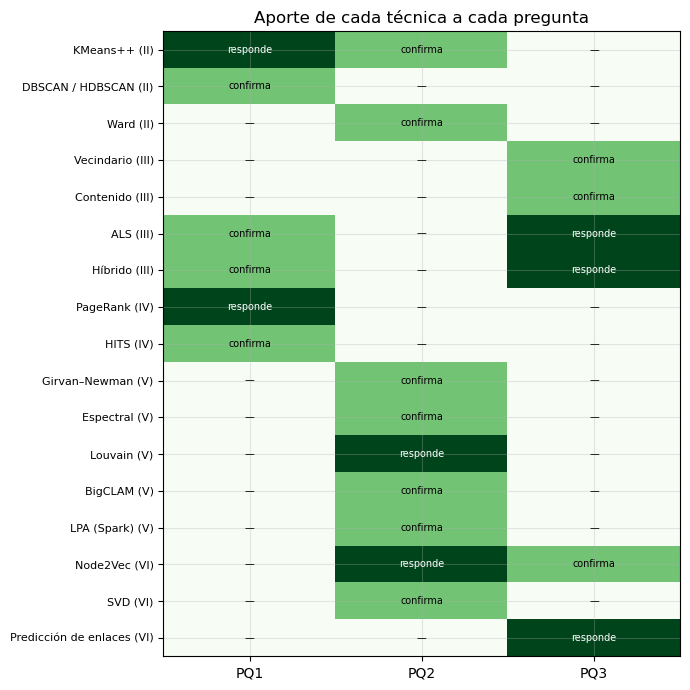

In [4]:
v_ = valor.set_index(valor.tecnica + " (" + valor.parte + ")")[["PQ1", "PQ2", "PQ3"]]
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(v_.to_numpy(), cmap="Greens", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(v_.columns); ax.set_yticks(range(len(v_))); ax.set_yticklabels(v_.index, fontsize=8)
for (r, c), x in np.ndenumerate(v_.to_numpy()):
    ax.text(c, r, ["—", "confirma", "responde"][x], ha="center", va="center", fontsize=7, color="w" if x == 2 else "k")
ax.set_title("Aporte de cada técnica a cada pregunta")
mostrar_fig("valor_tecnicas")

- **Aportaron más:** KMeans (PQ1), PageRank (PQ1), Louvain (PQ2), Node2Vec (PQ2 y PQ3), ALS y el híbrido (PQ3)

- **Aportaron poco por sí solos:** DBSCAN (un grupo gigante), Girvan–Newman (no escala)

- La grilla p × q de Node2Vec (el clique por proceso anula BFS/DFS) y GraphFrames (más lento y sin pesos)

- **Su valor fue de control:** Ward, espectral y Girvan–Newman **confirman** los resultados principales con otro método

---
### **2. ¿Convergen los resultados?**

- NMI y ARI entre las particiones de proveedores de clustering, Comunidades y Embeddings

- Atributos de rubro y región como referencia

- Cada par se compara **solo en los proveedores que tienen ambas etiquetas**

In [5]:
km = datos("02_Clustering", "kmeans_proveedor").set_index("proveedor_key").cluster
n5 = (datos("05_Comunidad", "nodos.parquet")[["idx", "clave"]]
        .merge(datos("05_Comunidad", "particion.parquet"), on="idx")
        .merge(datos("05_Comunidad", "bigclam.parquet")[["idx", "dominante"]], on="idx").set_index("clave"))
lpa = datos("05_Comunidad", "lpa.parquet").set_index("clave").lpa_sin_hubs
n6 = (datos("06_Representacion", "nodos.parquet")
        .merge(datos("06_Representacion", "latente_p1_q1.parquet")[["idx", "k6"]], on="idx").set_index("clave"))
P = {"tipología KMeans (II)": km, "Louvain (V)": n5.louvain, "BigCLAM dominante (V)": n5.dominante.where(n5.dominante >= 0),
     "LPA sin hubs (V)": lpa, "grupos latentes (VI)": n6.k6,
     "rubro: segmento": n6.segmento.where(~n6.segmento.isin(["SIN", "SI"])), "región": n6.region}
nombres = list(P)
filas = [{"a": a, "b": b, **comparar(P[a], P[b])} for i, a in enumerate(nombres) for b in nombres[i + 1:]]
convergencia = pd.DataFrame(filas)
convergencia.round(3)

,a,b,n,nmi,ari
0,tipología KMeans (II),Louvain (V),4311,0.100,0.020
1,tipología KMeans (II),BigCLAM dominante (V),4311,0.076,0.013
2,tipología KMeans (II),LPA sin hubs (V),11925,0.106,0.003
3,tipología KMeans (II),grupos latentes (VI),11662,0.089,0.030
4,tipología KMeans (II),rubro: segmento,11594,0.070,0.003
5,tipología KMeans (II),región,11662,0.035,-0.043
6,Louvain (V),BigCLAM dominante (V),7114,0.718,0.557
7,Louvain (V),LPA sin hubs (V),7114,0.815,0.672
8,Louvain (V),grupos latentes (VI),7114,0.530,0.274
9,Louvain (V),rubro: segmento,7113,0.652,0.347


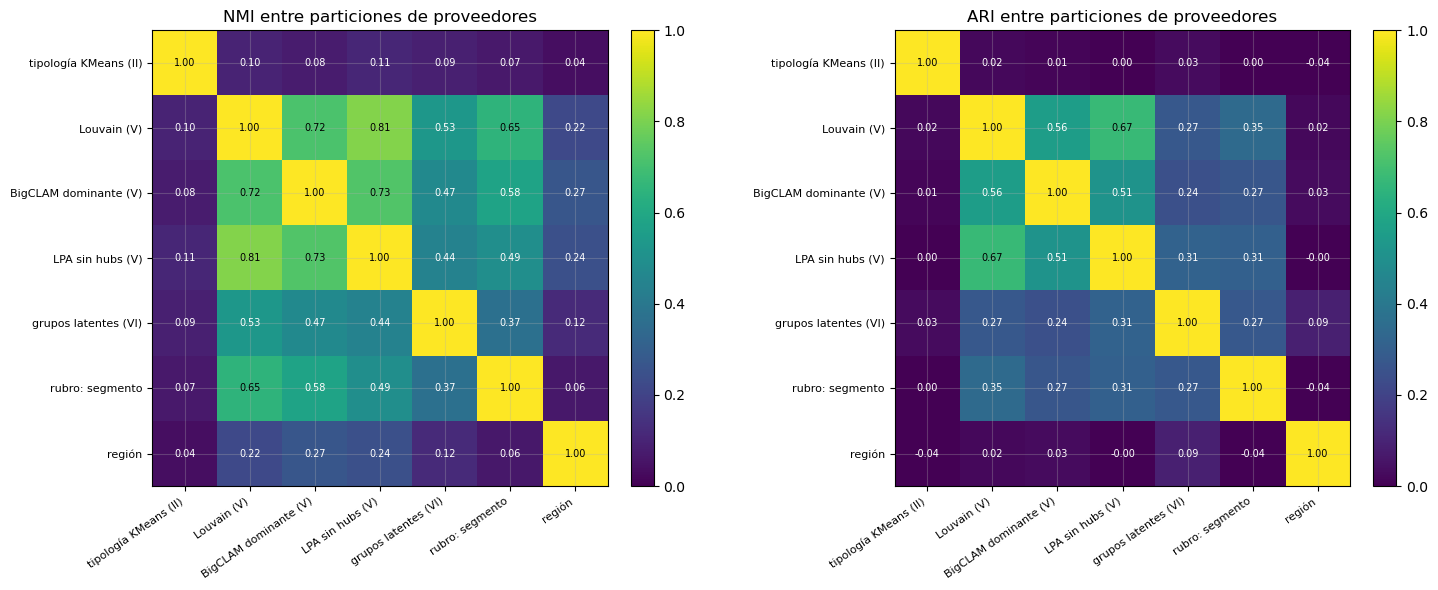

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a_, met in zip(ax, ["nmi", "ari"]):
    M_ = np.eye(len(nombres))
    for r in convergencia.itertuples():
        i, j = nombres.index(r.a), nombres.index(r.b)
        M_[i, j] = M_[j, i] = getattr(r, met)
    im = a_.imshow(M_, vmin=0, vmax=1, cmap="viridis")
    a_.set_xticks(range(len(nombres))); a_.set_xticklabels(nombres, rotation=35, ha="right", fontsize=8)
    a_.set_yticks(range(len(nombres))); a_.set_yticklabels(nombres, fontsize=8)
    for (r, c), x in np.ndenumerate(M_):
        a_.text(c, r, f"{x:.2f}", ha="center", va="center", fontsize=7, color="w" if x < .6 else "k")
    a_.set_title(f"{met.upper()} entre particiones de proveedores")
    plt.colorbar(im, ax=a_, fraction=.046, pad=.04)
mostrar_fig("convergencia")

- **Las técnicas de grafo convergen entre sí:** en el núcleo, Louvain coincide con LPA (NMI 0.81) y con BigCLAM (0.72)

- **Comunidades y embeddings convergen:** Louvain vs grupos latentes NMI 0.53 (41 vs 6 grupos: las comunidades se anidan)

- **Lo que comparten es el rubro:** NMI con el segmento de 0.65 (Louvain), 0.49 (LPA) y 0.37 (latentes)

- **Clústeres no convergen con nada** (NMI ≤ 0.11, ARI ≈ 0): agrupan por **comportamiento**, no por con quién se compite

- **ARI más bajo que NMI**: cada grupo latente junta varias comunidades

---
### **3. ¿Qué métodos escalaron y cuáles exigieron submuestra?**

In [7]:
E = lambda parte, tec, donde, escala, datos_, gana, pierde: dict(parte=parte, tecnica=tec, corre_en=donde, escala=escala, datos=datos_, se_gana=gana, se_pierde=pierde)
escalabilidad = pd.DataFrame([
    E("II", "KMeans++", "Spark MLlib", "completa", "13,317 proveedores, 2,696 entidades", "Todos los actores filtrados", "—"),
    E("II", "Ward", "scipy", "muestra", "5,000 proveedores", "Dendrograma y validación", "62% de los proveedores (matriz n²)"),
    E("III", "ALS", "Spark MLlib", "completa", "2,992 × 86,017", "Toda la matriz", "—"),
    E("III", "Contenido (HNSW)", "local", "completa, aproximada", "vecinos por texto", "Velocidad", "Nada: NDCG 0.0363 vs 0.0364 exacto"),
    E("IV", "PageRank", "Spark + scipy", "completa", "89k nodos, 136k aristas", "Todo el bipartito", "—"),
    E("V", "Girvan–Newman", "local", "muestra", "300 nodos", "Validar Louvain", "Todo el mercado: no escala"),
    E("V", "Espectral, Louvain, BigCLAM", "local", "núcleo", "7,114 nodos (12%), 22% del peso", "Calidad (Q 0.87) y métodos exactos", "Los proveedores esporádicos y los hubs"),
    E("V", "LPA", "Spark", "completa", "60k nodos, 1.6M aristas", "Todo el grafo, distribuible", "Calidad: Q 0.63-0.68, no converge"),
    E("VI", "Node2Vec", "local", "casi completa", "56,948 nodos (95%)", "Toda la periferia", "61 postores masivos"),
    E("VI", "UMAP", "local", "muestra", "15,000 nodos", "Mapa legible", "Solo para visualizar (el clustering usa todos)"),
    E("VI", "Enlaces", "local", "muestra", "50k + 50k pares", "Tiempo", "Nada: más pares no cambian las métricas")])
escalabilidad

,parte,tecnica,corre_en,escala,datos,se_gana,se_pierde
0,II,KMeans++,Spark MLlib,completa,"13,317 proveedores, 2,696 entidades",Todos los actores filtrados,—
1,II,Ward,scipy,muestra,"5,000 proveedores",Dendrograma y validación,62% de los proveedores (matriz n²)
2,III,ALS,Spark MLlib,completa,"2,992 × 86,017",Toda la matriz,—
3,III,Contenido (HNSW),local,"completa, aproximada",vecinos por texto,Velocidad,Nada: NDCG 0.0363 vs 0.0364 exacto
4,IV,PageRank,Spark + scipy,completa,"89k nodos, 136k aristas",Todo el bipartito,—
5,V,Girvan–Newman,local,muestra,300 nodos,Validar Louvain,Todo el mercado: no escala
6,V,"Espectral, Louvain, BigCLAM",local,núcleo,"7,114 nodos (12%), 22% del peso",Calidad (Q 0.87) y métodos exactos,Los proveedores esporádicos y los hubs
7,V,LPA,Spark,completa,"60k nodos, 1.6M aristas","Todo el grafo, distribuible","Calidad: Q 0.63-0.68, no converge"
8,VI,Node2Vec,local,casi completa,"56,948 nodos (95%)",Toda la periferia,61 postores masivos
9,VI,UMAP,local,muestra,"15,000 nodos",Mapa legible,Solo para visualizar (el clustering usa todos)


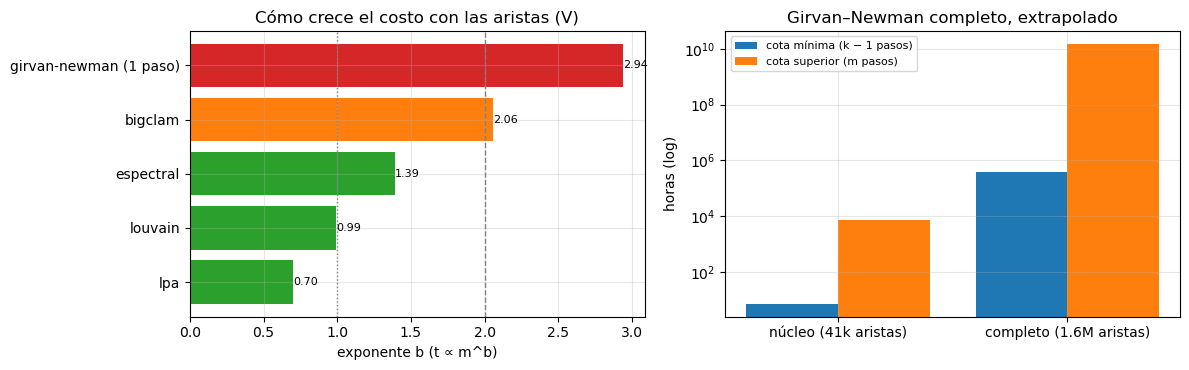

In [8]:
aj = tabla("05_Comunidad", "d_escalabilidad", "ajuste_costo").set_index("metodo").exponente
gne = tabla("05_Comunidad", "d_escalabilidad", "gn_extrapolacion").set_index("grafo")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
a_ = aj.sort_values()
ax[0].barh(a_.index, a_.values, color=["tab:green" if b < 1.5 else "tab:orange" if b < 2.5 else "tab:red" for b in a_.values])
for b, ls in ((1, ":"), (2, "--")):
    ax[0].axvline(b, ls=ls, c="gray", lw=1)
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", fontsize=8)
ax[0].set(xlabel="exponente b (t ∝ m^b)", title="Cómo crece el costo con las aristas (V)")
x_ = np.arange(2)
ax[1].bar(x_ - .2, gne.horas_minimo, .4, label="cota mínima (k − 1 pasos)")
ax[1].bar(x_ + .2, gne.horas_cota_superior, .4, label="cota superior (m pasos)")
ax[1].set_xticks(x_); ax[1].set_xticklabels(["núcleo (41k aristas)", "completo (1.6M aristas)"])
ax[1].set(yscale="log", ylabel="horas (log)", title="Girvan–Newman completo, extrapolado"); ax[1].legend(fontsize=8)
mostrar_fig("escalabilidad")

- **Escalaron sobre todo el dato:** KMeans, ALS y PageRank (Spark), LPA (Spark, 1.6M aristas) y Node2Vec (95% de los nodos)

- **Exigieron submuestra:** Ward (matriz n²), Girvan–Newman (un paso crece con m^2.9; completo ~7,300 h en el núcleo)

- **Qué se gana con el núcleo:** métodos exactos y de mayor calidad (Q 0.87 vs 0.63-0.68 de LPA en el grafo completo)

- **Qué se pierde:** la periferia y los esporádicos, que son justo el mundo de la cautividad (PQ1)

- **Qué se gana con LPA y Node2Vec:** cobertura total;

- **Qué se pierde:** precisión (LPA fragmenta) o interpretabilidad directa (dimensiones latentes sin nombre)

- **Aproximar no siempre cuesta:** HNSW iguala al contenido exacto y 50k pares de enlaces bastan

---
### **4. ¿Qué implicancias éticas tiene este análisis?**

#### a. Señales vs acusaciones

In [9]:
senales = pd.DataFrame([
    {"senal": "Grupos cerrados (11)", "parte": "V", "por_que_no_es_acusacion": "Coincidir mucho es típico de mercados chicos o especializados; la red no distingue un mercado de un acuerdo"},
    {"senal": "Coinciden y casi no ganan", "parte": "V", "por_que_no_es_acusacion": "Puede ser oferta de baja probabilidad, no acompañamiento"},
    {"senal": "Afinidades inusuales (5%)", "parte": "III", "por_que_no_es_acusacion": "Son relaciones únicas (una obra), con más competencia que el resto"},
    {"senal": "Postores masivos (61)", "parte": "V, VI", "por_que_no_es_acusacion": "Ofertar a miles de procesos es un patrón de oferta legal"},
    {"senal": "Entidades cautivas (30%)", "parte": "II, IV", "por_que_no_es_acusacion": "Depender de un consorcio de obra es esperable en entidades chicas con una obra grande"},
    {"senal": "Enlaces predichos", "parte": "VI", "por_que_no_es_acusacion": "Una afinidad estructural no implica que deban competir: especialización, capacidad, logística"}])
senales

,senal,parte,por_que_no_es_acusacion
0,Grupos cerrados (11),V,Coincidir mucho es típico de mercados chicos o especializados; la red no dis...
1,Coinciden y casi no ganan,V,"Puede ser oferta de baja probabilidad, no acompañamiento"
2,Afinidades inusuales (5%),III,"Son relaciones únicas (una obra), con más competencia que el resto"
3,Postores masivos (61),"V, VI",Ofertar a miles de procesos es un patrón de oferta legal
4,Entidades cautivas (30%),"II, IV",Depender de un consorcio de obra es esperable en entidades chicas con una ob...
5,Enlaces predichos,VI,"Una afinidad estructural no implica que deban competir: especialización, cap..."


- **Toda la salida es descriptiva:** comunidades, cautividad, afinidades y enlaces describen **patrones**

- **Un ranking no es una lista negra:** los grupos con nombre se presentan como **perfiles para revisión**

#### b. Transparencia

- **Datos abiertos:** OCDS del OECE (licencia CC BY 4.0); cualquiera puede reproducir el análisis con `pipeline.sh`

- **Decisiones explícitas:** cada parámetro (umbral de HHI, núcleo, γ, K, δ) está justificado y con su variación

#### c. Uso responsable

- **Revisión humana obligatoria** antes de publicar cualquier sospecha, con información que el OCDS no tiene

- **Personas naturales:** sus claves contienen DNI; solo se publican nombres ya públicos en el OCDS y agregados

- **Límites:** consorcios sin miembros, región del proveedor inferida, adjudicaciones sin estado, oferentes solo se registraron

---
### **5. ¿Cómo cambiarían las decisiones con mucho más volumen o cobertura?**

- Proyección del costo con los exponentes medidos en comunidades

- $t_0$ = tiempo medido en el núcleo, $b$ = exponente medido y $f$ = cuántas veces más aristas que el núcleo:

$$t(f) = t_0 \cdot f^{\,b}$$

In [10]:
rm = tabla("05_Comunidad", "d_escalabilidad", "resumen_metodos")
t0 = {"louvain": rm.loc[rm.metodo.str.startswith("louvain"), "seg"].iloc[0],
      "espectral": rm.loc[rm.metodo.str.startswith("espectral"), "seg"].iloc[0],
      "bigclam": rm.loc[rm.metodo.str.startswith("bigclam"), "seg"].iloc[0],
      "lpa": rm.loc[(rm.metodo == "LPA") & rm.grafo.str.contains("local"), "seg"].iloc[0],
      "girvan-newman (completo)": gne.loc["núcleo", "horas_cota_superior"] * 3600}
b_ = {**aj.drop("girvan-newman (1 paso)").to_dict(), "girvan-newman (completo)": aj["girvan-newman (1 paso)"] + 1}
F = [1, 10, 40, 100]
def legible(s):
    for u, d in (("años", 3.15e7), ("días", 86400), ("h", 3600), ("min", 60)):
        if s >= d: return f"{s / d:,.1f} {u}"
    return f"{s:.1f} s"
proyeccion = pd.DataFrame([{"metodo": m, "exponente": round(b_[m], 2), **{f"×{f}": legible(t0[m] * f ** b_[m]) for f in F}} for m in t0])
ward = pd.DataFrame([{"n": n, "memoria_GB": round(n ** 2 / 2 * 8 / 1e9, 1)} for n in (5_000, 13_317, 86_017, 860_170)])
display(proyeccion.rename(columns={"×1": "núcleo (×1)", "×40": "grafo completo (×40)"})); display(ward)

,metodo,exponente,núcleo (×1),×10,grafo completo (×40),×100
0,louvain,0.99,0.7 s,7.0 s,27.6 s,1.1 min
1,espectral,1.39,3.1 s,1.3 min,8.9 min,31.9 min
2,bigclam,2.06,2.9 s,5.5 min,1.6 h,10.6 h
3,lpa,0.70,0.4 s,2.0 s,5.3 s,10.1 s
4,girvan-newman (completo),3.94,304.5 días,"7,265.3 años","1,710,151.3 años","63,196,911.5 años"


,n,memoria_GB
0,5000,0.1
1,13317,0.7
2,86017,29.6
3,860170,2959.6


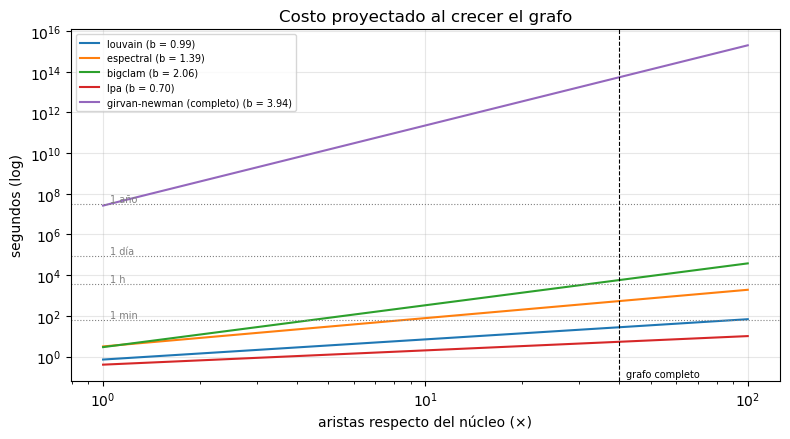

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
f_ = np.logspace(0, 2, 30)
for m in t0:
    ax.loglog(f_, t0[m] * f_ ** b_[m], label=f"{m} (b = {b_[m]:.2f})")
for s, lbl in ((60, "1 min"), (3600, "1 h"), (86400, "1 día"), (3.15e7, "1 año")):
    ax.axhline(s, ls=":", c="gray", lw=.8); ax.text(1.05, s * 1.3, lbl, fontsize=7, color="gray")
ax.axvline(40, ls="--", c="k", lw=.8); ax.text(42, 1e-1, "grafo completo", fontsize=7)
ax.set(xlabel="aristas respecto del núcleo (×)", ylabel="segundos (log)", title="Costo proyectado al crecer el grafo"); ax.legend(fontsize=7)
mostrar_fig("proyeccion")

- **Los métodos lineales siguen viables:** Louvain y LPA pasan de segundos a ~1 min con 100× aristas

- Proyección del LPA (5.3 s en el grafo completo) coincide con lo medido (7 s local)

- **Espectral y BigCLAM pasan a horas** (BigCLAM 1.6 h en el grafo completo, 10.6 h con 100×)

- **Girvan–Newman es imposible** a cualquier escala mayor que la muestra (~7,300 años con 10×)

- **Ward** pide 30 GB con todos los proveedores y 3 TB con 10×: KMeans en Spark lo reemplaza

#### a. Con mucho más volumen

- **Comunidades:** Louvain o Leiden distribuidos en lugar de los métodos exactos del núcleo

- **Embeddings:** paseos y Word2Vec distribuidos, o una GNN con muestreo de vecinos (GraphSAGE); UMAP solo sobre muestras

- **Núcleo más estricto** (más procesos compartidos) para que los métodos exactos sigan cabiendo

#### b. Con mucha más cobertura

- **Miembros de los consorcios:** serían nodos reales con aristas consorcio–empresa; cambiaría la lectura de la cautividad

- **Dirección del proveedor:** la región dejaría de inferirse de los procesos y se podría separar mejor mercado local

- **Estado adjudicaciones y oferentes:** aristas más limpias en el bipartito y en la co-participación

- **Familia para quienes nunca ganaron** (ítems): los atributos cubrirían a todos y la interpretación por rubro sería completa

- **Más años:** protocolos temporales más largos para enlaces y recomendación, y estabilidad de las comunidades en el tiempo

---
### **6. Verdades ocultas**

Lo que aparece al cruzar los resultados de varias partes

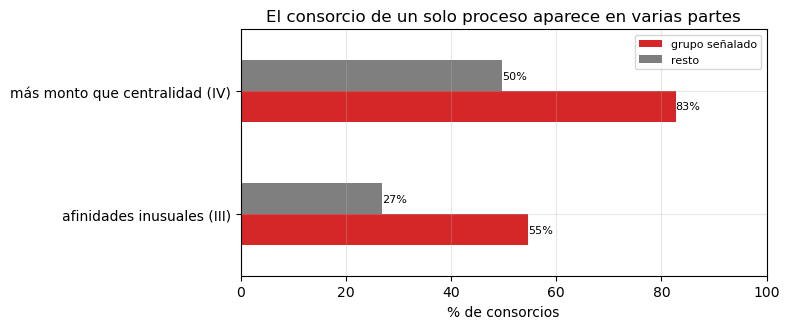

,grupo señalado,resto
afinidades inusuales (III),54.6,26.9
más monto que centralidad (IV),82.7,49.7


In [12]:
af = tabla("03_Recomend", "f_analisis", "afinidades_inusuales").set_index("grupo")
ct = tabla("04_PageRank", "d_analisis", "contraste_monto").set_index("grupo")
consorcio = pd.DataFrame({"grupo señalado": [af.loc["p ≤ 5%", "pct_consorcio"], ct.loc["más monto que centralidad", "pct_consorcio"]],
                          "resto": [af.loc["resto", "pct_consorcio"], ct.loc["resto", "pct_consorcio"]]},
                         index=["afinidades inusuales (III)", "más monto que centralidad (IV)"])
fig, ax = plt.subplots(figsize=(8, 3.4))
consorcio.plot.barh(ax=ax, color=["tab:red", "tab:gray"])
for c_ in ax.containers:
    ax.bar_label(c_, fmt="%.0f%%", fontsize=8)
ax.set(xlabel="% de consorcios", xlim=(0, 100), title="El consorcio de un solo proceso aparece en varias partes"); ax.legend(fontsize=8)
mostrar_fig("consorcios")
consorcio

- **El consorcio de un solo proceso une PQ1 y PQ3:** es el proveedor principal típico de las cautivas 

- La concentración del gasto pasa por actores que existen para un solo contrato

- **Rubro antes que región, dos veces:** comunidades y embeddings llegan a la misma estructura por caminos distintos

- **Los hubs no son grandes proveedores:** son **postores masivos**

- **La cautividad es local:** las cautivas están en la periferia de la red de compras y fuera de los mercados densos

- **Tipología y mercado:** clustering **cómo** se comporta un proveedor y comunidades/embeddings **con quién** compite

---
### **7. Escritura de resultados**

In [13]:
escritos = guardar_tablas({"valor_tecnicas": valor, "convergencia": convergencia, "escalabilidad": escalabilidad,
                           "senales": senales, "proyeccion": proyeccion, "ward_memoria": ward, "consorcios": consorcio.reset_index()})

Escrito en 07_Analisis/temp/c_insights/: valor_tecnicas, convergencia, escalabilidad, senales, proyeccion, ward_memoria, consorcios


#### a. Verificación

In [14]:
verificar_salidas(escritos)
assert convergencia.nmi.between(0, 1 + 1e-9).all(), "NMI fuera de [0, 1]"
print("NMI en [0, 1]")

OK: 7 tablas (parquet + json) | 5 figuras: consorcios, convergencia, escalabilidad, proyeccion, valor_tecnicas
NMI en [0, 1]


---
### **8. Cerrar sesión**

In [15]:
spark.stop()